In [10]:
import pandas as pd

# Open the World Bank file exactly as it is
raw = pd.read_excel("../data/raw/CMO-Historical-Data-Monthly.xlsx",
                    sheet_name="Monthly Prices", header=None)

# Find the row that holds the column names, and the two coffee columns
header_row = raw.index[raw.astype(str).apply(
    lambda r: r.str.contains("Coffee, Arabica", case=False).any(), axis=1)][0]
names = raw.iloc[header_row].astype(str)
arabica_col = names[names.str.contains("Coffee, Arabica", case=False)].index[0]
robusta_col = names[names.str.contains("Coffee, Robusta", case=False)].index[0]

# Keep only the month, Arabica and Robusta columns
coffee = raw.iloc[header_row + 1:, [0, arabica_col, robusta_col]].copy()
coffee.columns = ["month", "arabica", "robusta"]

# Keep only real data rows (months look like "2024M07")
coffee = coffee[coffee["month"].astype(str).str.match(r"^\d{4}M\d{2}$")]

# Turn "2024M07" into a real date, and prices into numbers
coffee["date"] = pd.to_datetime(coffee["month"].astype(str).str.replace("M", "-") + "-01")
coffee["arabica"] = pd.to_numeric(coffee["arabica"], errors="coerce")
coffee["robusta"] = pd.to_numeric(coffee["robusta"], errors="coerce")
coffee = coffee[["date", "arabica", "robusta"]].reset_index(drop=True)

# Save the clean table
coffee.to_csv("../data/processed/coffee_prices_monthly.csv", index=False)

print(len(coffee), "months, from", coffee["date"].min().date(), "to", coffee["date"].max().date())
print(coffee.tail())

802 months, from 1960-01-01 to 2026-10-01
          date  arabica  robusta
797 2026-06-01     6.79     3.73
798 2026-07-01     7.91     4.07
799 2026-08-01     7.97     3.98
800 2026-09-01     7.26     3.69
801 2026-10-01     7.40     3.63


FileNotFoundError: [Errno 2] No such file or directory: '../images/1_prices.png'

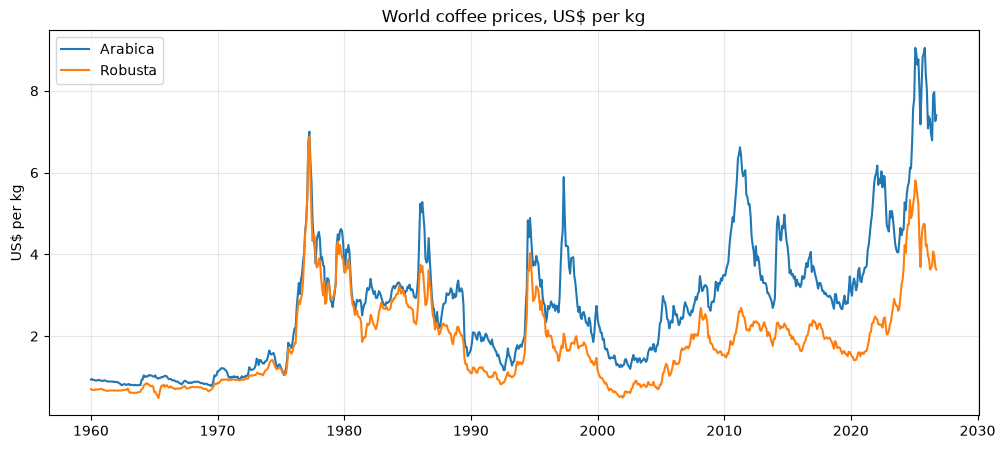

In [11]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))
plt.plot(coffee["date"], coffee["arabica"], label="Arabica")
plt.plot(coffee["date"], coffee["robusta"], label="Robusta")
plt.title("World coffee prices, US$ per kg")
plt.ylabel("US$ per kg")
plt.legend()
plt.grid(alpha=0.3)
plt.savefig("../images/1_prices.png", dpi=150, bbox_inches="tight")
plt.show()


Arabica reached a record nominal price of about $9/kg in 2025 and was still $7.40/kg in October 2026, while Robusta fell to $3.63/kg.

Long-run average: Arabica = 1.55x Robusta
October 2026:     Arabica = 2.04x Robusta


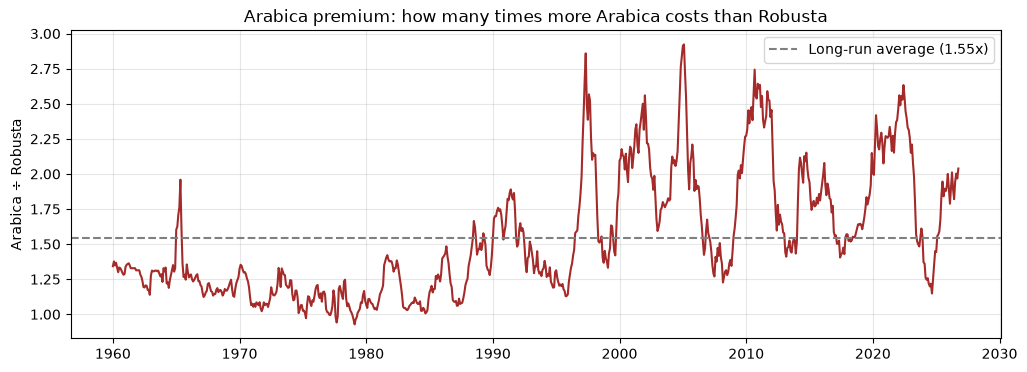

In [ ]:
# How many times more expensive is Arabica than Robusta?
coffee["ratio"] = coffee["arabica"] / coffee["robusta"]

long_run = coffee["ratio"].mean()
latest = coffee["ratio"].iloc[-1]
print(f"Long-run average: Arabica = {long_run:.2f}x Robusta")
print(f"October 2026:     Arabica = {latest:.2f}x Robusta")

# Chart the ratio over time
plt.figure(figsize=(12, 4))
plt.plot(coffee["date"], coffee["ratio"], color="brown")
plt.axhline(long_run, linestyle="--", color="gray", label=f"Long-run average ({long_run:.2f}x)")
plt.title("Arabica premium: how many times more Arabica costs than Robusta")
plt.ylabel("Arabica ÷ Robusta")
plt.legend()
plt.grid(alpha=0.3)
plt.savefig("../images/2_premium.png", dpi=150, bbox_inches="tight")
plt.show()


The Arabica premium has two eras: stable (1.0–1.4x) under the coffee quota system until 1989, and volatile (1.2–2.9x) since. In 2024 the premium nearly vanished (≈1.2x) as Robusta spiked; by October 2026 it had recovered to 2.04x.

In [ ]:
# Compare today's premium with the modern era only (after the quota system ended)
modern = coffee[coffee["date"] >= "1990-01-01"]

modern_avg = modern["ratio"].mean()
pct_rank = (modern["ratio"] < latest).mean() * 100

print(f"Average since 1990:  {modern_avg:.2f}x")
print(f"October 2026:        {latest:.2f}x")
print(f"Today's premium is higher than {pct_rank:.0f}% of months since 1990")

Average since 1990:  1.82x
October 2026:        2.04x
Today's premium is higher than 69% of months since 1990


At 2.04x in October 2026, the Arabica premium is above its post-1990 average of 1.82x, higher than 69% of months since 1990.

Typical monthly price swing by decade:
        Arabica (% swing)  Robusta (% swing)
decade                                      
1960                  3.1                4.6
1970                  8.0                7.7
1980                  7.1                6.6
1990                 10.1                8.3
2000                  6.0                6.9
2010                  6.2                4.4
2020                  6.5                6.5

Arabica, last 12 months: 7.3% typical monthly swing
Arabica, average since 1990: 6.6%


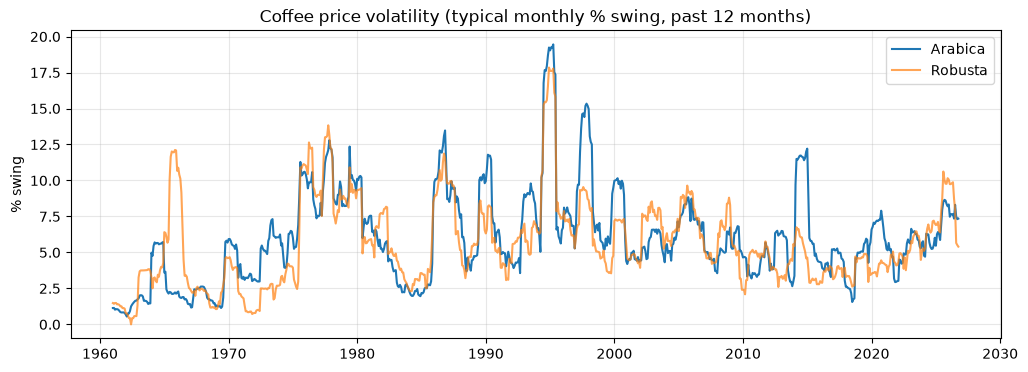

In [ ]:
# 1. Monthly % change in price
coffee["arabica_change"] = coffee["arabica"].pct_change() * 100
coffee["robusta_change"] = coffee["robusta"].pct_change() * 100

# 2. Volatility = how spread out the last 12 monthly changes are
coffee["arabica_vol"] = coffee["arabica_change"].rolling(12).std()
coffee["robusta_vol"] = coffee["robusta_change"].rolling(12).std()

# 3. Typical monthly swing by decade
coffee["decade"] = (coffee["date"].dt.year // 10) * 10
by_decade = coffee.groupby("decade")[["arabica_change", "robusta_change"]].std().round(1)
by_decade.columns = ["Arabica (% swing)", "Robusta (% swing)"]
print("Typical monthly price swing by decade:")
print(by_decade)

print(f"\nArabica, last 12 months: {coffee['arabica_vol'].iloc[-1]:.1f}% typical monthly swing")
print(f"Arabica, average since 1990: {coffee.loc[coffee['date'] >= '1990-01-01', 'arabica_vol'].mean():.1f}%")

# Chart
plt.figure(figsize=(12, 4))
plt.plot(coffee["date"], coffee["arabica_vol"], label="Arabica")
plt.plot(coffee["date"], coffee["robusta_vol"], label="Robusta", alpha=0.7)
plt.title("Coffee price volatility (typical monthly % swing, past 12 months)")
plt.ylabel("% swing")
plt.legend()
plt.grid(alpha=0.3)
plt.savefig("../images/3_volatility.png", dpi=150, bbox_inches="tight")
plt.show()

Model's average error:        19.0%
'Price stays same' error:     17.8%

Forecast for Oct 2027: $7.40/kg (80% range: $4.97 - $11.02)


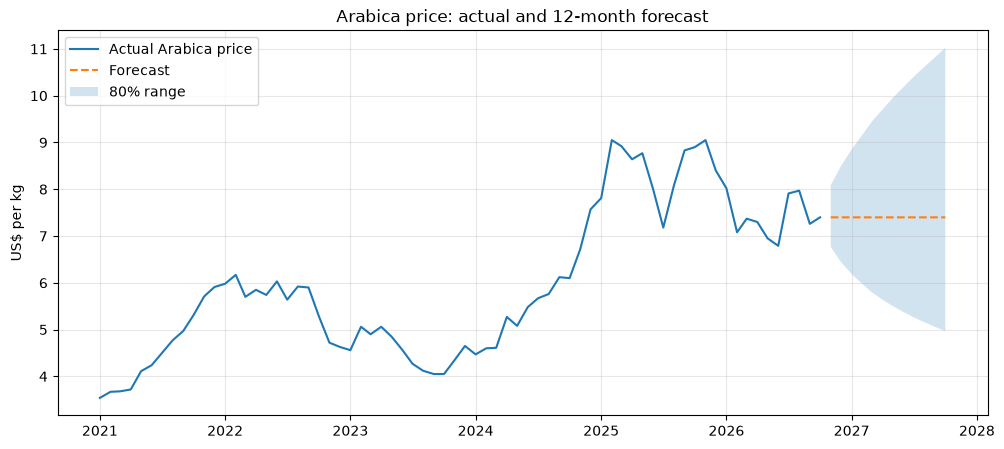

In [ ]:
import numpy as np
from statsmodels.tsa.arima.model import ARIMA

# Use the modern era only (after 1990), as a proper monthly series
s = coffee.set_index("date")["arabica"]
s = s[s.index >= "1990-01-01"].asfreq("MS")

# ---- 1. TEST: pretend it's Oct 2025 and forecast the next 12 months ----
train, test = s[:-12], s[-12:]
test_model = ARIMA(np.log(train), order=(1, 1, 1)).fit()
pred = np.exp(test_model.forecast(12))
naive = np.full(12, train.iloc[-1])          # simple guess: price stays the same

mape_model = (abs(pred.values - test.values) / test.values).mean() * 100
mape_naive = (abs(naive - test.values) / test.values).mean() * 100
print(f"Model's average error:        {mape_model:.1f}%")
print(f"'Price stays same' error:     {mape_naive:.1f}%")

# ---- 2. FORECAST: use all data to forecast Nov 2026 - Oct 2027 ----
model = ARIMA(np.log(s), order=(1, 1, 1)).fit()
fc = model.get_forecast(12)
fc_mid = np.exp(fc.predicted_mean)
fc_range = np.exp(fc.conf_int(alpha=0.2))    # 80% range

print(f"\nForecast for Oct 2027: ${fc_mid.iloc[-1]:.2f}/kg "
      f"(80% range: ${fc_range.iloc[-1, 0]:.2f} - ${fc_range.iloc[-1, 1]:.2f})")

# ---- 3. CHART ----
recent = s[s.index >= "2021-01-01"]
plt.figure(figsize=(12, 5))
plt.plot(recent.index, recent, label="Actual Arabica price")
plt.plot(fc_mid.index, fc_mid, linestyle="--", label="Forecast")
plt.fill_between(fc_mid.index, fc_range.iloc[:, 0], fc_range.iloc[:, 1],
                 alpha=0.2, label="80% range")
plt.title("Arabica price: actual and 12-month forecast")
plt.ylabel("US$ per kg")
plt.legend()
plt.grid(alpha=0.3)
plt.savefig("../images/4_forecast.png", dpi=150, bbox_inches="tight")
plt.show()

A standard ARIMA model did not beat a ‘no-change’ forecast in a 12-month backtest (19.0% vs 17.8% average error), consistent with commodity prices behaving close to a random walk. The useful output is the uncertainty: the 80% range for October 2027 is $4.97–$11.02/kg.”

In [ ]:
# Ethiopia's 2025/26 exports (ECTA figures reported in the news)
volume_tonnes = 400_000        # about 400,000 tonnes
eth_price_now = 7_500          # about $7,500 per tonne
today = s.iloc[-1]             # world Arabica today ($7.40/kg)

scenarios = {
    "Low (bottom of 80% range)": fc_range.iloc[-1, 0],
    "Middle (no change)":         fc_mid.iloc[-1],
    "High (top of 80% range)":    fc_range.iloc[-1, 1],
}

print("If volumes stay the same, Ethiopia's yearly coffee export revenue would be:\n")
for name, world_price in scenarios.items():
    change = world_price / today                      # % move in world price
    revenue = volume_tonnes * eth_price_now * change / 1e9
    print(f"{name:28s} world ${world_price:5.2f}/kg -> about ${revenue:.1f} billion")

If volumes stay the same, Ethiopia's yearly coffee export revenue would be:

Low (bottom of 80% range)    world $ 4.97/kg -> about $2.0 billion
Middle (no change)           world $ 7.40/kg -> about $3.0 billion
High (top of 80% range)      world $11.02/kg -> about $4.5 billion


If coffee volumes hold steady, Ethiopia’s yearly coffee export revenue could plausibly range from about $2.0 billion to $4.5 billion by late 2027, depending only on world Arabica prices. That’s $1 billion of downside and $1.5 billion of upside from one source of risk.